# Decision Trees Exercises

![DecisionTree.png](Assets/DecisionTree.png)


# Цели обучения

- Распознайте деревья решений и как их использовать для проблем классификации
- Узнайте, как определить наилучшее разделение и факторы для разделения
- Объясните сильные и слабые стороны деревьев для принятия решений
- Объясните, как деревья регрессии помогают классифицировать непрерывные значения
- Примените расширение Intel® для Scikit-learn*, чтобы использовать базовые вычислительные возможности оборудования




## Введение

Мы будем использовать набор данных качества вина для этих упражнений. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (3-9, где самый высокий - лучше) и цвет (красный или белый). Имя файла - «Wine_Quality_Data.csv».

In [1]:
from __future__ import print_function
import os
data_path = ['data']

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

from sklearnex import patch_sklearn
patch_sklearn()


Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные и изучите функции.
* Мы будем использовать их все для прогнозирования `color` (белого или красного), но функция цветов должна быть закодирована на целое число.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context('notebook')
%matplotlib inline

filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath, sep=',')
data.head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [4]:
data.describe()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


Преобразуйте цветовую функцию в целое число. Это быстрый способ сделать это с помощью  Pandas.

In [5]:
# Преобразуем color в целое число: 1 = red, 0 = white
data['color'] = (data['color'] == 'red').astype(int)
data['color'].value_counts()


color
0    4898
1    1599
Name: count, dtype: int64

## Вопрос 2

* Используйте `StratifiedShuffleSplit` для разделения данных на наборы поездов и тестов, которые стратифицированы по качеству вина. Если возможно, сохраните индексы доли для вопроса 5 ниже.
* Проверьте процентный состав каждого уровня качества для наборов данных о поезде и тестовых данных.

In [6]:
# Предсказываем color, используя все остальные признаки (включая quality).
# Стратифицируем разбиение по quality, чтобы сохранить распределение качества в train/test.
feature_cols = [c for c in data.columns if c != 'color']

strat_shuff_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

train_idx, test_idx = next(strat_shuff_split.split(data[feature_cols], data['quality']))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'color']

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'color']


Теперь проверьте процентную долю каждого уровня качества в обучающем и тестовом наборах данных. Как видно ниже, набор данных в основном состоит из белого вина.

In [7]:
train_quality_pct = data.loc[train_idx, 'quality'].value_counts(normalize=True).sort_index() * 100
test_quality_pct = data.loc[test_idx, 'quality'].value_counts(normalize=True).sort_index() * 100

comparison = pd.concat([train_quality_pct, test_quality_pct], axis=1)
comparison.columns = ['train', 'test']
comparison


,train,test
quality,,
3,0.461843,0.461538
4,3.320871,3.333333
5,32.900814,32.923077
6,43.655157,43.641026
7,16.604355,16.615385
8,2.968991,2.974359
9,0.087970,0.051282


## Вопрос 3

* Постройте классификатор на основе дерева решений без ограничений на максимальную глубину, количество признаков или количество листьев.
* Определите, сколько узлов присутствует в этом (очень большом) дереве и какова его глубина.
* Используя это дерево, оцените погрешность прогнозирования на обучающем и тестовом наборах данных. Как вы думаете, что здесь происходит, исходя из различий в погрешности прогнозирования?

In [8]:
dt = DecisionTreeClassifier(random_state=42)
dt = dt.fit(X_train, y_train)


In [9]:
def measure_error(y_true, y_pred, label):
    return pd.Series({
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'f1': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }, name=label)

y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)

train_test_full_error = pd.concat([
    measure_error(y_train, y_train_pred, 'train'),
    measure_error(y_test, y_test_pred, 'test')
], axis=1)

train_test_full_error


,train,test
accuracy,0.99956,0.986154
precision,0.99956,0.986116
recall,0.99956,0.986154
f1,0.99956,0.986126


Количество узлов и максимальная фактическая глубина.

In [10]:
print('Количество узлов:', dt.tree_.node_count)
print('Максимальная глубина:', dt.tree_.max_depth)


Количество узлов: 143
Максимальная глубина: 20


Дерево решений демонстрирует чуть более точные прогнозы на обучающих данных, чем на тестовых, что свидетельствует о (незначительной) переобученности. Также обратите внимание на идеальный показатель воспроизводимости для обучающих данных. Во многих случаях разница в точности прогнозов бывает даже больше, чем показано здесь.

## Вопрос 4

* С помощью сетчатого поиска с перекрестной валидацией найдите дерево решений, которое демонстрирует хорошие результаты на тестовом наборе данных. Присвойте этой модели дерева решений другое имя переменной, чем в вопросе 3, чтобы обе модели можно было использовать в вопросе 6.
* Определите количество узлов и глубину этого дерева.
* Рассчитайте погрешности на обучающем и тестовом наборах данных, как и ранее, и сравните их с погрешностями дерева из вопроса 3.

In [11]:
param_grid = {
    'max_depth': range(1, 20),
    'max_features': range(1, X_train.shape[1] + 1)
}

GR = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid=param_grid, scoring='accuracy', cv=5, n_jobs=-1)
GR = GR.fit(X_train, y_train)

GR.best_estimator_


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in th

In [12]:
dt_gr = GR.best_estimator_

y_train_pred_gr = dt_gr.predict(X_train)
y_test_pred_gr = dt_gr.predict(X_test)

train_test_gr_error = pd.concat([
    measure_error(y_train, y_train_pred_gr, 'train'),
    measure_error(y_test, y_test_pred_gr, 'test')
], axis=1)

train_test_gr_error


,train,test
accuracy,0.995601,0.990256
precision,0.995614,0.990240
recall,0.995601,0.990256
f1,0.995591,0.990245


Количество узлов и максимальная глубина дерева.

In [13]:
print('Количество узлов:', dt_gr.tree_.node_count)
print('Максимальная глубина:', dt_gr.tree_.max_depth)


Количество узлов: 95
Максимальная глубина: 8


Эти ошибки тестирования немного лучше, чем предыдущие. Таким образом, можно сделать вывод, что в предыдущем примере имело место переобучение, но лишь в незначительной степени.

## Вопрос 5

* Снова разделите данные на части `X` и `y`, на этот раз с `residual_sugar` в качестве прогнозируемых (`y`) данных. *Примечание:* если индексы были сохранены из результатов `StratifiedShuffleSplit` в вопросе 2, их можно использовать повторно для разделения данных.
* Используя поиск по сетке с перекрестной валидацией, найдите модель **регрессии** на основе дерева решений, которая хорошо работает на тестовом наборе данных.
* Оцените погрешности на обучающем и тестовом наборах данных с помощью среднеквадратичной ошибки.
* Постройте график, на котором будут отображены фактические *и* прогнозируемые значения остаточного сахара.

In [14]:
# Используем те же индексы train/test из Q2, но теперь предсказываем residual_sugar
feature_cols_sugar = [c for c in data.columns if c != 'residual_sugar']

X_train_s = data.loc[train_idx, feature_cols_sugar]
y_train_s = data.loc[train_idx, 'residual_sugar']

X_test_s = data.loc[test_idx, feature_cols_sugar]
y_test_s = data.loc[test_idx, 'residual_sugar']

param_grid_reg = {
    'max_depth': range(1, 20),
    'max_features': range(1, X_train_s.shape[1] + 1)
}

GR_sugar = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid=param_grid_reg, scoring='neg_mean_squared_error', cv=5, n_jobs=-1)
GR_sugar = GR_sugar.fit(X_train_s, y_train_s)

dt_sugar = GR_sugar.best_estimator_
dt_sugar


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",15
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``m

Количество узлов и максимальная глубина дерева. В этом дереве много узлов, что неудивительно, учитывая непрерывный характер данных.

In [15]:
print('Количество узлов:', dt_sugar.tree_.node_count)
print('Максимальная глубина:', dt_sugar.tree_.max_depth)


Количество узлов: 4233
Максимальная глубина: 15


Ошибка на обучающем и тестовом наборах данных. Поскольку речь идет о непрерывных величинах, мы будем использовать среднеквадратичную ошибку.

In [16]:
y_train_s_pred = dt_sugar.predict(X_train_s)
y_test_s_pred = dt_sugar.predict(X_test_s)

train_mse = mean_squared_error(y_train_s, y_train_s_pred)
test_mse = mean_squared_error(y_test_s, y_test_s_pred)

print(f'MSE на обучающем наборе: {train_mse:.4f}')
print(f'MSE на тестовом наборе: {test_mse:.4f}')


MSE на обучающем наборе: 0.0811
MSE на тестовом наборе: 2.8571


График, отражающий соотношение фактического и прогнозируемого остаточного содержания сахара.

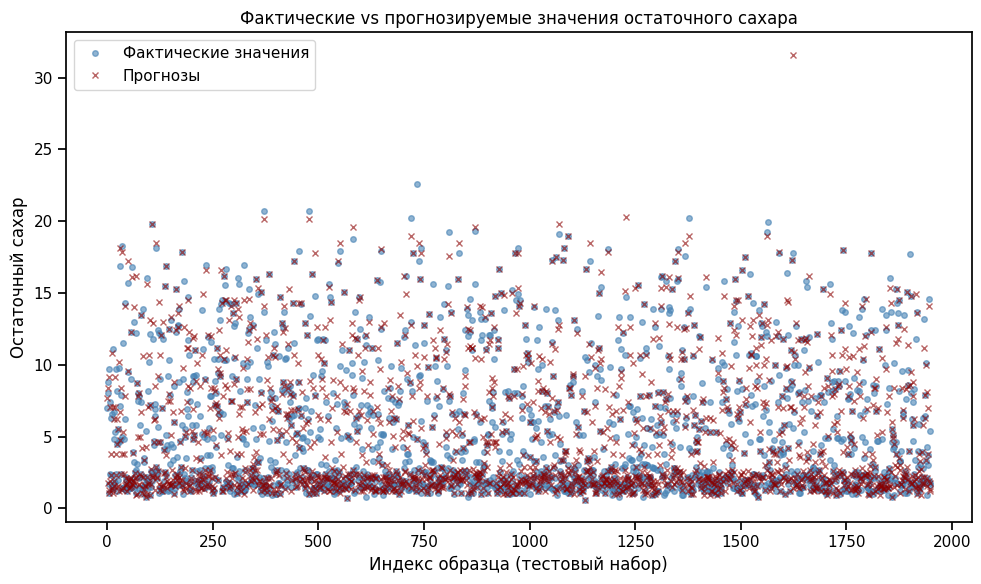

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(len(y_test_s)), y_test_s.values, marker='o', ls='', ms=4, color='steelblue', label='Фактические значения', alpha=0.6)
ax.plot(range(len(y_test_s)), y_test_s_pred, marker='x', ls='', ms=4, color='darkred', label='Прогнозы', alpha=0.6)
ax.set_xlabel('Индекс образца (тестовый набор)')
ax.set_ylabel('Остаточный сахар')
ax.set_title('Фактические vs прогнозируемые значения остаточного сахара')
ax.legend()
plt.tight_layout()
plt.show()


## Вопрос 6 *(Необязательный)*

Этот вопрос является необязательным, так как для его решения требуется дополнительная программа командной строки (GraphViz) и библиотека Python (PyDotPlus). GraphViz можно установить с помощью менеджера пакетов в Linux и Mac. Для установки библиотеки PyDotPlus можно использовать либо `pip`, либо `conda` (`conda install -c conda-forge pydotplus`).

После установки этих программ:

* Создайте визуализацию дерева решений из вопроса 3, в котором предсказывался цвет вина, а количество признаков и/или разбиений не ограничено.
* Создайте визуализацию дерева решений из вопроса 4, в котором предсказывался цвет вина, но для нахождения оптимальной глубины и количества признаков использовался поиск по сетке.

Дерево решений из вопроса 5, скорее всего, будет иметь слишком много узлов для визуализации.

In [18]:
try:
    import pydotplus
    pydotplus_installed = True

except:
    print('PyDotPlus must be installed to execute the remainder of the cells associated with this question.')
    print('Please see the instructions for this question for details.')
    pydotplus_installed = False


PyDotPlus must be installed to execute the remainder of the cells associated with this question.
Please see the instructions for this question for details.


Дерево из вопроса 3.

Дерево, построенное с помощью перекрестной валидации из вопроса 4. Это дерево намного менее глубокое, чем предыдущее.